# 03 · Song outcomes, robustness and observed history

Continue with **v1 only**. Main-paper Figure 3A/B compares independent demand with social success. We reproduce that descriptive relationship and add robustness checks and recorded-history exports. None of these gives a new causal effect of musical “quality” itself.

We use full independent-world shares for the song benchmark (as in Figure 3), while notebook 02 uses random control halves for sample-size-matched market comparisons. Do not conflate these denominators.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib, io, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works from the notebook folder, experiment folder, or repository root.
here = Path.cwd()
candidates = [here, here.parent] + list(here.glob('experiment2*'))
ROOT = next(p for p in candidates if (p / 'musiclab_data.zip').exists())
ARCHIVE = ROOT / 'musiclab_data.zip'
OUT = ROOT / 'outputs' / 'v1-reproduction'
OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 125, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
SOCIAL = '#7959a6'
CONTROL = '#42755c'

def read_table(name):
    with zipfile.ZipFile(ARCHIVE) as z:
        return pd.read_csv(io.BytesIO(z.read(name)), header=None, comment='%', skipinitialspace=True)

def shares(counts):
    counts = np.asarray(counts, dtype=float)
    assert counts.sum() > 0
    return counts / counts.sum()

def gini(values):
    values = np.asarray(values, dtype=float)
    assert np.all(values >= 0) and values.sum() > 0
    return np.abs(values[:, None] - values[None, :]).sum() / (2 * len(values) * values.sum())

def save_figure(fig, name):
    fig.savefig(FIG / (name+'.png'), dpi=180, bbox_inches='tight')
    fig.savefig(FIG / (name+'.svg'), bbox_inches='tight')
    plt.show()

metadata = pd.read_csv(ROOT / 'data/song_metadata.csv', dtype={'song_id':str})
totals = read_table('downloads_v1_lexorder.txt')
song_ids = totals[0].astype(str).tolist()
assert metadata.song_id.tolist() == song_ids


In [2]:
counts = totals.iloc[:,1:].to_numpy(dtype=int).T
market_shares = counts/counts.sum(axis=1,keepdims=True)
# Competition/min ranks: ties share rank; a display-only tie order may use song_id.
ranks = np.array([pd.Series(row).rank(method='min',ascending=False).astype(int).to_numpy() for row in counts])
rows=[]
for w in range(9):
    for j,song_id in enumerate(song_ids):
        rows.append({'world':w+1,'song_id':song_id,'downloads':int(counts[w,j]),
                     'share':float(market_shares[w,j]),'rank':int(ranks[w,j])})
song_worlds=pd.DataFrame(rows)
song_worlds.to_csv(OUT/'song_worlds.csv',index=False)
summary=metadata.copy()
summary['independent_share']=market_shares[8]
summary['independent_rank']=ranks[8]
summary['social_mean_share']=market_shares[:8].mean(axis=0)
summary['social_min_rank']=ranks[:8].min(axis=0)
summary['social_max_rank']=ranks[:8].max(axis=0)
summary['rank_span']=summary.social_max_rank-summary.social_min_rank
summary['song_unpredictability']=[np.mean([abs(market_shares[a,j]-market_shares[b,j]) for a,b in combinations(range(8),2)]) for j in range(48)]
summary.to_csv(OUT/'song_summary.csv',index=False)
example=summary.sort_values(['rank_span','song_id'],ascending=[False,True]).iloc[0]
print('Illustrative example selected by largest rank span (not an independent test):')
display(example[['song_id','artist','title','independent_rank','social_min_rank','social_max_rank']])


Illustrative example selected by largest rank span (not an independent test):


song_id                306121
artist              silverfox
title                    gnaw
independent_rank           30
social_min_rank             7
social_max_rank            45
Name: 10, dtype: object

## Appeal is related to success, but does not determine a unique outcome
Each dot below represents one song in one social world. The x-axis is that song's outcome in the independent condition. The diagonal means equal outcomes. The cubic line is an optional descriptive fit mirroring the paper's plotting choice; it is not a causal model, not a confidence band, and is never extrapolated beyond observed x-values.

The paper calls independent demand “quality.” Here we label it **independent demand / appeal benchmark**, because it combines the music, names, choices and this participant population. Tied ranks use competition ranks; the paper does not specify its tie convention, so exact rank-coordinate equivalence is not asserted.

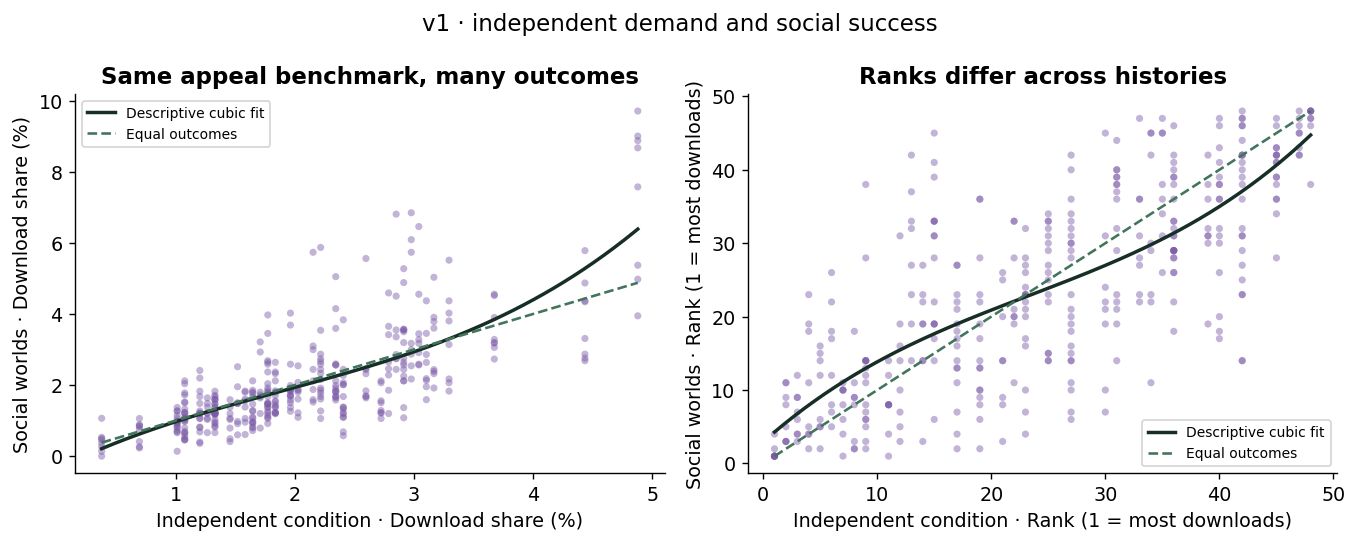

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
curve_rows=[]
for ax,all_values,label,scale in [(axes[0],market_shares,'Download share (%)',100),(axes[1],ranks,'Rank (1 = most downloads)',1)]:
    x=np.tile(all_values[8]*scale,8);y=all_values[:8].reshape(-1)*scale
    ax.scatter(x,y,s=17,color=SOCIAL,alpha=.45,edgecolors='none')
    grid=np.linspace(float(x.min()),float(x.max()),160)
    fit=np.polynomial.Polynomial.fit(x,y,3)
    ax.plot(grid,fit(grid),color='#172e27',lw=2,label='Descriptive cubic fit')
    ax.plot(grid,grid,'--',color=CONTROL,label='Equal outcomes')
    ax.set(xlabel='Independent condition · '+label,ylabel='Social worlds · '+label)
    ax.legend(fontsize=8)
    curve_rows.extend({'metric':'share' if scale==100 else 'rank','x':float(a/scale),'y':float(b/scale)} for a,b in zip(grid,fit(grid)))
axes[0].set_title('Same appeal benchmark, many outcomes');axes[1].set_title('Ranks differ across histories')
fig.suptitle('v1 · independent demand and social success');fig.tight_layout()
save_figure(fig,'03_song_outcomes')
pd.DataFrame(curve_rows).to_csv(OUT/'descriptive_cubic_curves.csv',index=False)


## Robustness: does the result depend on Gini?
Repeat the same original 1,000 random halves using the original seed. **HHI** sums squared shares; **CV** divides the population SD of shares by their mean. Both measure concentration differently. This is a sensitivity check on the metric, not two additional independent experiments or a search for a favorable p-value.

In [4]:
control=read_table('dynamics_downloads_w9_v1.txt').iloc[:,2:].to_numpy(dtype=int)
def concentration(m):return np.array([gini(m),np.square(m).sum(),m.std(ddof=0)/m.mean()])
rng=np.random.default_rng(20261125);baseline=np.empty((1000,3))
for b in range(1000):
    idx=rng.permutation(len(control))[:len(control)//2]
    baseline[b]=concentration(shares(control[idx].sum(0)))
social=np.array([concentration(m) for m in market_shares[:8]])
robust=pd.DataFrame({'metric':['gini','hhi','cv'],'independent_split_mean':baseline.mean(0),
                    'social_world_mean':social.mean(0),'social_world_min':social.min(0),
                    'comparison_fraction':[(social[:,j,None]<baseline[:,j]).mean() for j in range(3)]})
np.testing.assert_allclose(baseline[:,0],pd.read_csv(OUT/'control_splits.csv').gini,rtol=0,atol=1e-14)
robust.to_csv(OUT/'robustness_metrics.csv',index=False);display(robust.round(5))


,metric,independent_split_mean,social_world_mean,social_world_min,comparison_fraction
0,gini,0.25778,0.34022,0.28377,0.01075
1,hhi,0.02543,0.03090,0.02716,0.00200
2,cv,0.46863,0.68676,0.55102,0.00200


## Supporting descriptive check: ratings and downloads
Recreate the idea of supplement Figure S8: do observed ratings agree with download behavior? Ratings are self-selected, post-treatment outcomes; conditioning on who listened or rated does **not** isolate a causal effect on taste. Zero ratings are missing and excluded. Because some download records lack a listen record, song-level conditional rates below use only recorded listeners.

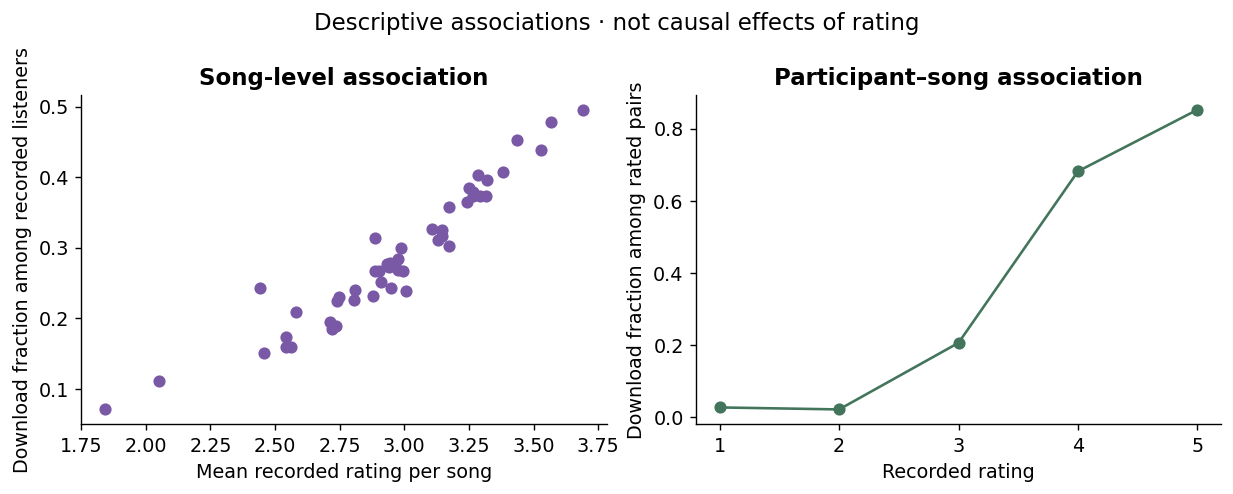

In [5]:
listen_total=np.zeros(48);download_among_listeners=np.zeros(48);rating_sum=np.zeros(48);rating_n=np.zeros(48)
rating_counts=np.zeros(5,dtype=int);rating_downloads=np.zeros(5,dtype=int)
for w in range(1,10):
    ds=read_table(f'dynamics_downloads_w{w}_v1.txt').set_index(0).sort_index()
    ls=read_table(f'dynamics_listens_w{w}_v1.txt').set_index(0).reindex(ds.index)
    rs=read_table(f'dynamics_ratings_w{w}_v1.txt').set_index(0).reindex(ds.index)
    d,l,r=[a.iloc[:,1:].to_numpy(dtype=int) for a in [ds,ls,rs]]
    listen_total+=l.sum(0);download_among_listeners+=((d==1)&(l==1)).sum(0)
    rating_sum+=r.sum(0);rating_n+=(r>0).sum(0)
    for star in range(1,6):
        rating_counts[star-1]+=(r==star).sum();rating_downloads[star-1]+=((r==star)&(d==1)).sum()
ratings=pd.DataFrame({'stars':range(1,6),'rated_pairs':rating_counts,'downloaded_pairs':rating_downloads,
                      'download_fraction':rating_downloads/rating_counts})
ratings.to_csv(OUT/'rating_download_association.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].scatter(rating_sum/rating_n,download_among_listeners/listen_total,color=SOCIAL)
ax[0].set(xlabel='Mean recorded rating per song',ylabel='Download fraction among recorded listeners',title='Song-level association')
ax[1].plot(range(1,6),rating_downloads/rating_counts,'o-',color=CONTROL)
ax[1].set(xlabel='Recorded rating',ylabel='Download fraction among rated pairs',title='Participant–song association',xticks=range(1,6))
fig.suptitle('Descriptive associations · not causal effects of rating');fig.tight_layout();save_figure(fig,'04_ratings_and_downloads')


## Replay only observed, retained downloads
For the website we aggregate the timestamped download indicators by calendar day. Exclude the three all-zero rows: a row is not necessarily a download. Include the initial zero state; all world timelines use the same daily calendar, forward-filling days with no downloads. Timestamps are recorded New York local time; no invented within-day ordering is added.

This replay represents retained downloads, not participants arriving and not an exact reconstruction of the original screen counters (excluded activity may have appeared there). Independent counts are shown for analysis, although original independent participants did not see them. No participant IDs leave this notebook.

This is an **additional view**, not a claim to have exactly reproduced supplement S9/S10's participant-indexed curves.

Exported 68 calendar days plus an initial zero state; all nine final vectors reconcile.


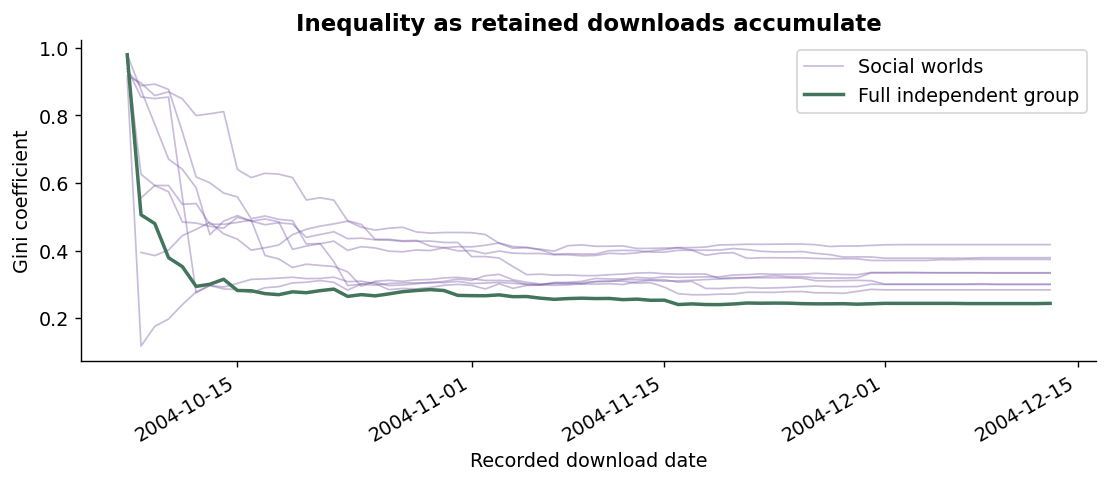

In [6]:
events_by_world={};all_dates=[]
for w in range(1,10):
    ev=read_table(f'dynamics_downloads_download_w{w}_v1.txt')
    flags=ev.iloc[:,2:50].to_numpy(dtype=int)
    keep=flags.sum(1)==1
    dates=pd.to_datetime(ev.loc[keep,50]).dt.normalize()
    daily=pd.DataFrame(flags[keep],columns=song_ids).groupby(dates.to_numpy()).sum()
    events_by_world[w]=daily;all_dates.extend(daily.index)
calendar=pd.date_range(min(all_dates),max(all_dates),freq='D')
replay=[];daily_metrics=[]
for w in range(1,10):
    daily=events_by_world[w].reindex(calendar,fill_value=0)
    cumulative=daily.cumsum().to_numpy(dtype=int)
    np.testing.assert_array_equal(cumulative[-1],counts[w-1])
    history=np.vstack([np.zeros(48,dtype=int),cumulative])
    replay.append({'world':w,'counts':history.tolist()})
    for i,row in enumerate(history):
        daily_metrics.append({'world':w,'step':i,'downloads':int(row.sum()),
                              'gini':gini(row) if row.sum() else None})
replay_payload={'schema_version':1,'version':1,'clock':'New York local calendar day',
                'scope':'Cumulative retained unique user-song download events; not original visible counters',
                'song_ids':song_ids,'dates':[None]+[d.strftime('%Y-%m-%d') for d in calendar],
                'worlds':replay}
(OUT/'daily_history.json').write_text(json.dumps(replay_payload,separators=(',',':'),allow_nan=False)+'\n')
pd.DataFrame(daily_metrics).to_csv(OUT/'daily_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
for record in replay:
    y=[gini(row) if sum(row)>0 else np.nan for row in record['counts']]
    ax.plot(calendar,y[1:],color=CONTROL if record['world']==9 else SOCIAL,
            alpha=1 if record['world']==9 else .4,lw=2 if record['world']==9 else 1,
            label='Full independent group' if record['world']==9 else ('Social worlds' if record['world']==1 else None))
ax.set(title='Inequality as retained downloads accumulate',xlabel='Recorded download date',ylabel='Gini coefficient')
ax.legend();fig.autofmt_xdate();fig.tight_layout();save_figure(fig,'05_recorded_history')
print(f'Exported {len(calendar)} calendar days plus an initial zero state; all nine final vectors reconcile.')


## Supplementary participant-prefix reconstruction
To inspect stability with increasing participation, order the released participant matrices by user ID and accumulate each participant's retained choices. IDs are used as a registration-order proxy because later v1 registration timestamps are invalid. Returning actions, excluded activity and the original authors' exact trajectory algorithm cannot be recovered. Thus these are **documented reconstructed prefix curves**, not exact historical display counts or exact S9/S10 replications.

Compare at common prefix sizes through 699 (the smallest social world). Independent prefixes come from random participant orders, split into two disjoint halves. Intervals of the split values describe partition variability, not effect confidence intervals. Endpoints at different actual world sizes remain the authoritative final analysis in notebook 02.

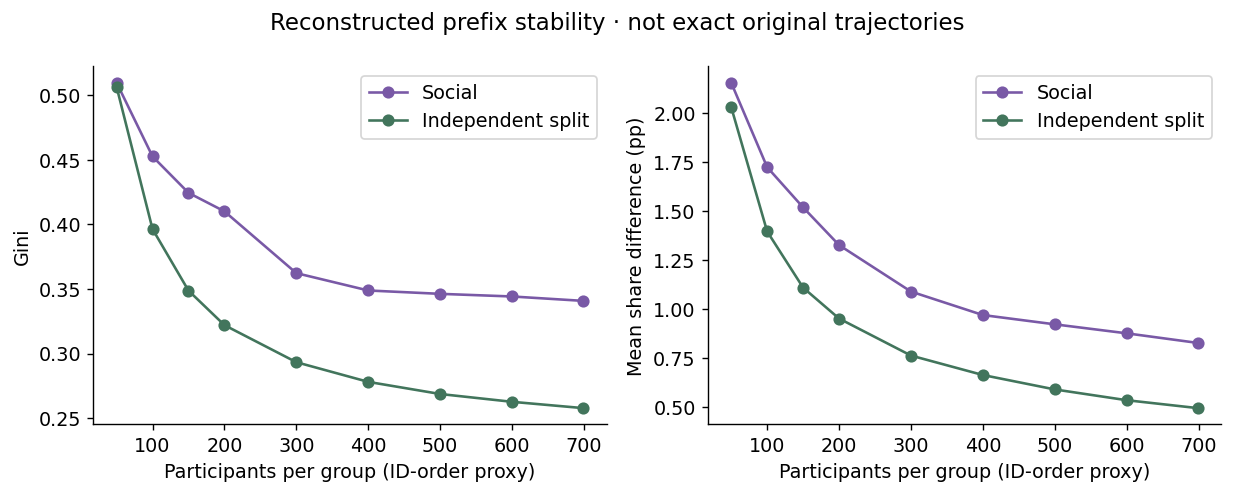

In [7]:
prefix_n=np.array([50,100,150,200,300,400,500,600,699])
social_prefix=[]
for w in range(1,9):
    frame=read_table(f'dynamics_downloads_w{w}_v1.txt').sort_values(0)
    social_prefix.append(frame.iloc[:,2:].to_numpy(dtype=int).cumsum(0)[prefix_n-1])
social_prefix=np.array(social_prefix)
rng=np.random.default_rng(20261127)
ctrl_g=np.empty((1000,len(prefix_n)));ctrl_u=np.empty_like(ctrl_g)
for b in range(1000):
    order=rng.permutation(len(control));a,c=np.array_split(order,[len(control)//2])
    ac=control[a].cumsum(0);cc=control[c].cumsum(0)
    for k,npeople in enumerate(prefix_n):
        ma,mc=shares(ac[npeople-1]),shares(cc[npeople-1])
        ctrl_g[b,k]=gini(ma);ctrl_u[b,k]=np.abs(ma-mc).mean()
trajectory=[]
for k,npeople in enumerate(prefix_n):
    ms=np.array([shares(v) for v in social_prefix[:,k,:]])
    trajectory.append({'participants_per_group':int(npeople),'social_gini_mean':float(np.mean([gini(v) for v in ms])),
                       'control_gini_mean':float(ctrl_g[:,k].mean()),
                       'social_u':float(np.mean([np.abs(ms[a]-ms[b]).mean() for a,b in combinations(range(8),2)])),
                       'control_u_mean':float(ctrl_u[:,k].mean())})
trajectory=pd.DataFrame(trajectory);trajectory.to_csv(OUT/'reconstructed_prefix_metrics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,scol,ccol,label,factor in [(axes[0],'social_gini_mean','control_gini_mean','Gini',1),(axes[1],'social_u','control_u_mean','Mean share difference (pp)',100)]:
    ax.plot(prefix_n,trajectory[scol]*factor,'o-',color=SOCIAL,label='Social');ax.plot(prefix_n,trajectory[ccol]*factor,'o-',color=CONTROL,label='Independent split')
    ax.set(xlabel='Participants per group (ID-order proxy)',ylabel=label);ax.legend()
fig.suptitle('Reconstructed prefix stability · not exact original trajectories');fig.tight_layout();save_figure(fig,'06_prefix_stability')
